In [1]:
from pathlib import Path
import xarray as xr

data_dir = Path(r"C:\Users\chris\Documents\MAT 257\Project 2\Data")
nc_files = sorted(data_dir.glob("*.nc"))

# Longitude: 12°W to 4°E
# Latitude: 49°N to 61°N

def select_britain(ds):
    # Handle either ascending or descending latitude
    if ds.lat[0] < ds.lat[-1]:
        lat_slice = slice(49, 61)
    else:
        lat_slice = slice(61, 49)

    return ds.sel(
        lat=lat_slice,
        lon=slice(-12, 4)
    )

ds_gb = xr.open_mfdataset(
    nc_files,
    combine="by_coords",
    preprocess=select_britain,
    parallel=True,
    chunks={"time": 100}
)

print(ds_gb)

<xarray.Dataset> Size: 58MB
Dimensions:                  (time: 308, lat: 48, lon: 64)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2022-04-30 ... 2022-10-01
  * lat                      (lat) float32 192B 49.12 49.38 ... 60.62 60.88
  * lon                      (lon) float32 256B -11.88 -11.62 ... 3.625 3.875
Data variables: (12/17)
    sea_surface_temperature  (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    sst_dtime                (time, lat, lon) float64 8MB dask.array<chunksize=(2, 48, 48), meta=np.ndarray>
    dt_analysis              (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    sses_bias                (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    sses_standard_deviation  (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta=np.ndarray>
    diurnal_amplitude        (time, lat, lon) float32 4MB dask.array<chunksize=(2, 48, 64), meta

In [2]:
month_data = ds_gb[
    [
        "sea_surface_temperature",
        "wind_speed",
        "water_vapor"
    ]
].sel(
    time=slice("2022-07-01", "2022-07-31T23:59:59")
)

variables = [
    "sea_surface_temperature",
    "wind_speed",
    "water_vapor"
]

points_month = (
    month_data[variables]
    .to_dataframe()
    .reset_index()
    .rename(
        columns={
            "sea_surface_temperature": "temperature"
        }
    )
)

In [28]:
coarse_data = (
    month_data
    .coarsen(
        lat=2,
        lon=2,
        boundary="trim"
    )
    .mean()
)

points_coarse = (
    coarse_data
    .to_dataframe()
    .reset_index()
    .rename(
        columns={
            "sea_surface_temperature": "temperature"
        }
    )
    .dropna(
        subset=[
            "temperature",
            "wind_speed",
            "water_vapor"
        ]
    )
)

print("Original observations:", len(points_month))
print("Coarsened observations:", len(points_coarse))

Original observations: 190464
Coarsened observations: 17352


In [3]:
points_month

,time,lat,lon,temperature,wind_speed,water_vapor
0,2022-07-01,49.125,-11.875,NaN,NaN,15.899998
1,2022-07-01,49.125,-11.625,NaN,NaN,16.199997
2,2022-07-01,49.125,-11.375,NaN,NaN,16.499998
3,2022-07-01,49.125,-11.125,NaN,NaN,16.199997
4,2022-07-01,49.125,-10.875,NaN,NaN,16.199997
...,...,...,...,...,...,...
190459,2022-07-31,60.875,2.875,288.149994,4.199999,14.099998
190460,2022-07-31,60.875,3.125,290.699982,3.799999,13.799997
190461,2022-07-31,60.875,3.375,NaN,NaN,13.499998
190462,2022-07-31,60.875,3.625,NaN,NaN,12.599997


In [29]:
points_coarse

,time,lat,lon,temperature,wind_speed,water_vapor
11,2022-07-01,49.25,-6.25,288.825012,6.649999,17.249998
12,2022-07-01,49.25,-5.75,288.599976,6.400000,18.149998
13,2022-07-01,49.25,-5.25,288.225006,6.399999,18.599998
14,2022-07-01,49.25,-4.75,288.449982,6.799999,18.974998
32,2022-07-01,49.75,-11.75,287.024994,7.599999,15.899998
...,...,...,...,...,...,...
47611,2022-07-31,60.75,1.75,288.562500,4.599999,14.399998
47612,2022-07-31,60.75,2.25,289.125000,4.499999,14.474998
47613,2022-07-31,60.75,2.75,287.774994,4.199999,14.174997
47614,2022-07-31,60.75,3.25,289.849976,3.466666,13.349998


In [30]:
model_variables = [
    "temperature",
    "wind_speed",
    "water_vapor"
]

n_time_records = month_data.sizes["time"]

coverage = (
    points_coarse
    .groupby(["lat", "lon"])[model_variables]
    .count()
    / n_time_records
)

coverage["minimum_coverage"] = coverage.min(axis=1)

coverage.head()

temperature  wind_speed  water_vapor  minimum_coverage
lat   lon                                                           
49.25 -11.75     0.838710    0.838710     0.838710          0.838710
      -11.25     0.838710    0.838710     0.838710          0.838710
      -10.75     0.838710    0.838710     0.838710          0.838710
      -10.25     0.758065    0.758065     0.758065          0.758065
      -9.75      0.758065    0.758065     0.758065          0.758065

In [31]:
min_coverage = 0.20

eligible_coords = coverage[
    coverage["minimum_coverage"] >= min_coverage
].reset_index()

print("Eligible coordinates:", len(eligible_coords))

Eligible coordinates: 383


In [33]:
len(points_coarse[["lat", "lon"]].drop_duplicates())

406

<Axes: >

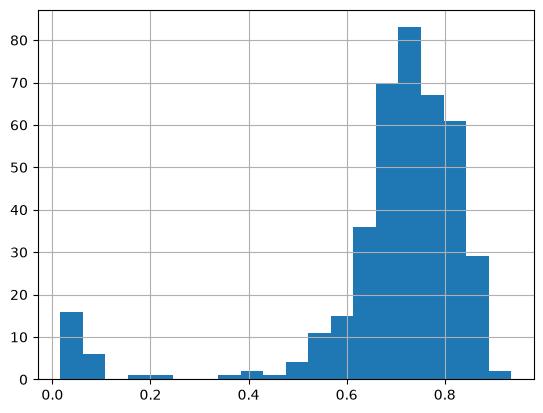

In [34]:
coverage["minimum_coverage"].hist(bins=20)

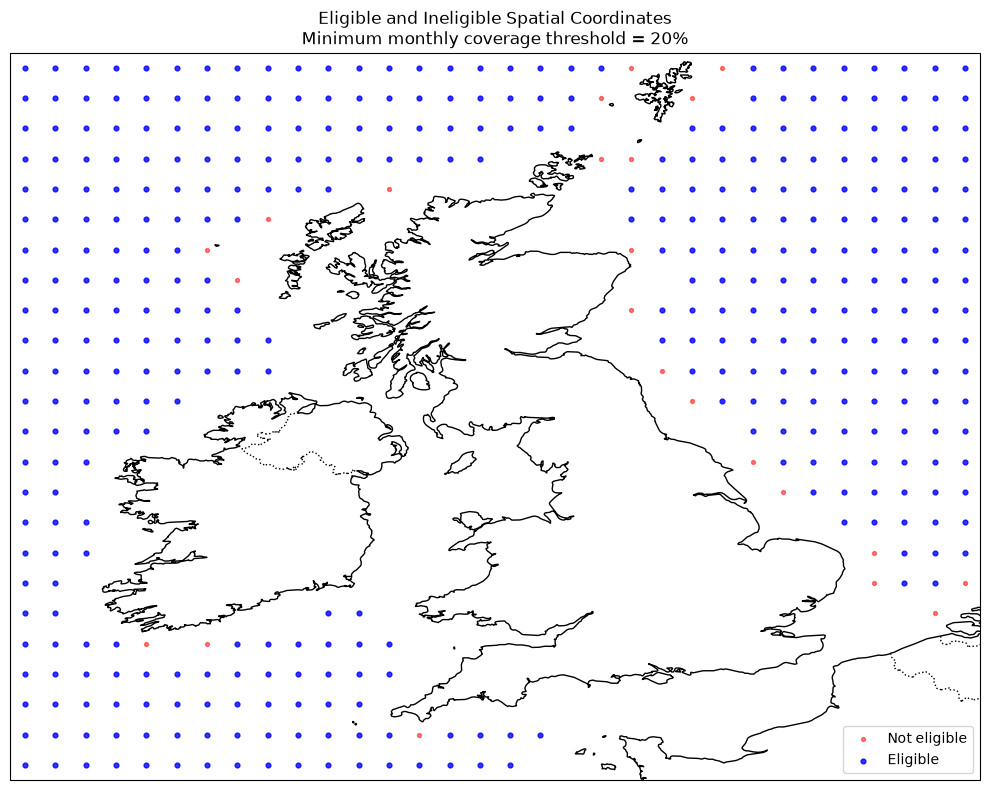

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

all_coords = points_coarse[
    ["lat", "lon"]
].drop_duplicates()

coverage_plot = (
    coverage["minimum_coverage"]
    .reset_index()
    .rename(columns={
        "minimum_coverage": "coverage"
    })
)

plot_coords = all_coords.merge(
    coverage_plot,
    on=["lat", "lon"],
    how="left"
)

min_coverage = 0.20

plot_coords["eligible"] = (
    plot_coords["coverage"] >= min_coverage
)

fig, ax = plt.subplots(
    figsize=(10, 8),
    subplot_kw={
        "projection": ccrs.PlateCarree()
    }
)

# Plot non-eligible points first
not_eligible = plot_coords[
    ~plot_coords["eligible"]
]

ax.scatter(
    not_eligible["lon"],
    not_eligible["lat"],
    color="red",
    s=8,
    alpha=0.5,
    transform=ccrs.PlateCarree(),
    label="Not eligible"
)

# Plot eligible points on top
eligible = plot_coords[
    plot_coords["eligible"]
]

ax.scatter(
    eligible["lon"],
    eligible["lat"],
    color="blue",
    s=12,
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    label="Eligible"
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.set_extent(
    [-12, 4, 49, 61],
    crs=ccrs.PlateCarree()
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Eligible and Ineligible Spatial Coordinates\n"
    f"Minimum monthly coverage threshold = {min_coverage:.0%}"
)

ax.legend()
plt.tight_layout()
plt.show()

In [37]:
eligible_coords

,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage
0,49.25,-11.75,0.838710,0.838710,0.838710,0.838710
1,49.25,-11.25,0.838710,0.838710,0.838710,0.838710
2,49.25,-10.75,0.838710,0.838710,0.838710,0.838710
3,49.25,-10.25,0.758065,0.758065,0.758065,0.758065
4,49.25,-9.75,0.758065,0.758065,0.758065,0.758065
...,...,...,...,...,...,...
378,60.75,1.75,0.645161,0.645161,0.645161,0.645161
379,60.75,2.25,0.596774,0.596774,0.596774,0.596774
380,60.75,2.75,0.580645,0.580645,0.580645,0.580645
381,60.75,3.25,0.596774,0.596774,0.596774,0.596774


In [38]:
cleaned = points_coarse.merge(eligible_coords[["lat", "lon", "minimum_coverage"]], how="inner", on=["lat", "lon"])
cleaned

,time,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage
0,2022-07-01,49.25,-6.25,288.825012,6.649999,17.249998,0.725806
1,2022-07-01,49.25,-5.75,288.599976,6.400000,18.149998,0.741935
2,2022-07-01,49.25,-5.25,288.225006,6.399999,18.599998,0.741935
3,2022-07-01,49.25,-4.75,288.449982,6.799999,18.974998,0.709677
4,2022-07-01,49.75,-11.75,287.024994,7.599999,15.899998,0.838710
...,...,...,...,...,...,...,...
17283,2022-07-31,60.75,1.75,288.562500,4.599999,14.399998,0.645161
17284,2022-07-31,60.75,2.25,289.125000,4.499999,14.474998,0.596774
17285,2022-07-31,60.75,2.75,287.774994,4.199999,14.174997,0.580645
17286,2022-07-31,60.75,3.25,289.849976,3.466666,13.349998,0.596774


In [39]:
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",   # longitude/latitude
    "EPSG:3034",   # European Lambert Conformal Conic
    always_xy=True
)

cleaned["x"], cleaned["y"] = transformer.transform(
    cleaned["lon"].to_numpy(),
    cleaned["lat"].to_numpy()
)

# Get the day within the month
cleaned["time_days"] = (
    cleaned["time"] - cleaned["time"].min()
).dt.total_seconds() / (24 * 60 * 60)

cleaned

,time,lat,lon,temperature,wind_speed,water_vapor,minimum_coverage,x,y,time_days
0,2022-07-01,49.25,-6.25,288.825012,6.649999,17.249998,0.725806,2.866348e+06,2.629729e+06,0.0
1,2022-07-01,49.25,-5.75,288.599976,6.400000,18.149998,0.741935,2.900691e+06,2.622175e+06,0.0
2,2022-07-01,49.25,-5.25,288.225006,6.399999,18.599998,0.741935,2.935084e+06,2.614853e+06,0.0
3,2022-07-01,49.25,-4.75,288.449982,6.799999,18.974998,0.709677,2.969527e+06,2.607763e+06,0.0
4,2022-07-01,49.75,-11.75,287.024994,7.599999,15.899998,0.838710,2.507925e+06,2.779475e+06,0.0
...,...,...,...,...,...,...,...,...,...,...
17283,2022-07-31,60.75,1.75,288.562500,4.599999,14.399998,0.645161,3.559358e+06,3.771089e+06,30.0
17284,2022-07-31,60.75,2.25,289.125000,4.499999,14.474998,0.596774,3.585963e+06,3.768197e+06,30.0
17285,2022-07-31,60.75,2.75,287.774994,4.199999,14.174997,0.580645,3.612586e+06,3.765486e+06,30.0
17286,2022-07-31,60.75,3.25,289.849976,3.466666,13.349998,0.596774,3.639227e+06,3.762955e+06,30.0


In [40]:
import pandas as pd
cleaned = cleaned.reset_index(drop=True).copy()

unique_coords = cleaned[["lat", "lon"]].drop_duplicates()

n_test_coords = max(
    1,
    int(round(0.20 * len(unique_coords)))
)

test_coords = unique_coords.sample(
    n=n_test_coords,
    random_state=0
)

test_keys = pd.MultiIndex.from_frame(test_coords)
df_keys = pd.MultiIndex.from_frame(cleaned[["lat", "lon"]])

cleaned["set"] = np.where(
    df_keys.isin(test_keys),
    "test",
    "train"
)

train = cleaned[cleaned["set"] == "train"].copy()
test = cleaned[cleaned["set"] == "test"].copy()

In [41]:
train_keys = set(zip(train["lat"], train["lon"]))
test_keys = set(zip(test["lat"], test["lon"]))

print("Train rows:", len(train))
print("Test rows:", len(test))
print("Train coordinates:", len(train_keys))
print("Test coordinates:", len(test_keys))
print("Overlap:", len(train_keys & test_keys))

Train rows: 13798
Test rows: 3490
Train coordinates: 306
Test coordinates: 77
Overlap: 0


In [65]:
train_small = (
    train
    .groupby(["lat", "lon"], group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 20),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

In [68]:
features = [
    "x",
    "y",
    "time_days",
    "water_vapor",
    "wind_speed"
]

model_columns = features + ["temperature"]

train_model = (
    train_small
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=model_columns)
    .copy()
)

test_model = (
    test
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=model_columns)
    .copy()
)

X_train = train_model[features]
y_train = train_model["temperature"]

X_test = test_model[features]
y_test = test_model["temperature"]

print(X_train.isna().sum())
print(y_train.isna().sum())

print("Training observations:", len(train_model))
print("Testing observations:", len(test_model))

x              0
y              0
time_days      0
water_vapor    0
wind_speed     0
dtype: int64
0
Training observations: 6114
Testing observations: 3490


In [69]:
X_train

,x,y,time_days,water_vapor,wind_speed
0,2.492342e+06,2.728073e+06,11.000000,17.849997,2.849999
1,2.492342e+06,2.728073e+06,24.000000,23.099998,8.199999
2,2.492342e+06,2.728073e+06,27.000000,28.724998,3.349999
3,2.492342e+06,2.728073e+06,7.004167,22.649998,6.649999
4,2.492342e+06,2.728073e+06,25.000000,17.924999,10.849999
...,...,...,...,...,...
6109,3.665885e+06,3.760604e+06,28.000000,14.849998,4.666666
6110,3.665885e+06,3.760604e+06,22.000000,18.449997,6.299999
6111,3.665885e+06,3.760604e+06,28.000000,15.974998,2.266666
6112,3.665885e+06,3.760604e+06,23.000000,15.824997,7.800000


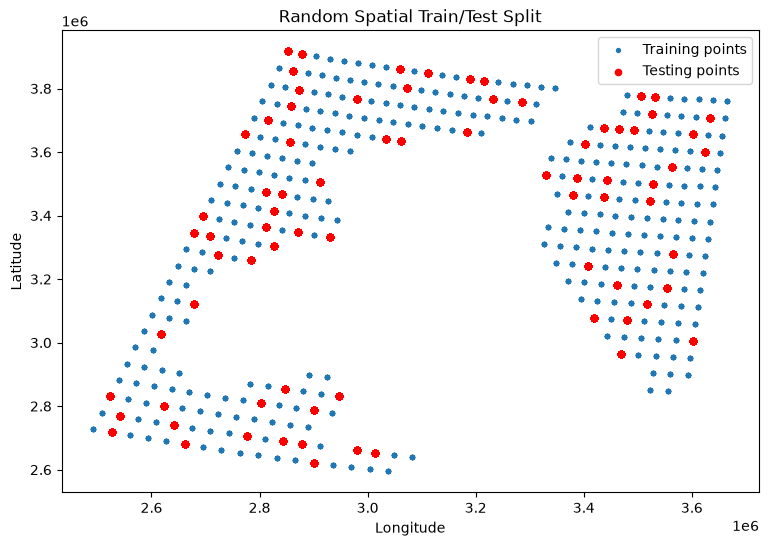

In [60]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_train["x"], X_train["y"],
    s=8, label="Training points"
)

plt.scatter(
    X_test["x"], X_test["y"],
    s=20, color="red", label="Testing points"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Random Spatial Train/Test Split")
plt.legend()
plt.show()

In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [71]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, DotProduct, RBF, ExpSineSquared, ConstantKernel, WhiteKernel
from sklearn.metrics import mean_squared_error, mean_absolute_error

kernel_specs = {
    "Matern_32": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=1.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "Matern_52": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=2.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "RBF": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * RBF(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    )

#     "DotProduct": (
#         ConstantKernel(
#             1.0,
#             constant_value_bounds=(1e-3, 1e3)
#         )
#         * DotProduct(
#             sigma_0=1.0,
#             sigma_0_bounds=(1e-3, 1e3)
#         )
#         + WhiteKernel(
#             noise_level=1.0,
#             noise_level_bounds=(1e-4, 1e2)
#         )
#     )
}


models = {}

for kernel_name, kernel in kernel_specs.items():

    model = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-4,
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=42
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    models[kernel_name] = model

batch_size = 500

all_predictions = {}
all_uncertainties = {}

for kernel_name, model in models.items():

    predictions = []
    uncertainties = []

    for start in range(0, len(test_model), batch_size):
        stop = start + batch_size

        X_batch = X_test_scaled[start:stop]

        pred, std = model.predict(
            X_batch,
            return_std=True
        )

        predictions.extend(pred)
        uncertainties.extend(std)

    all_predictions[kernel_name] = np.array(predictions)
    all_uncertainties[kernel_name] = np.array(uncertainties)

    
prediction_results = test_model.copy()

for kernel_name in models:
    prediction_results[
        f"{kernel_name}_prediction"
    ] = all_predictions[kernel_name]

    prediction_results[
        f"{kernel_name}_uncertainty"
    ] = all_uncertainties[kernel_name]
    

metrics = []

for kernel_name in models:

    y_pred = all_predictions[kernel_name]
    y_true = test_model["temperature"].to_numpy()

    metrics.append({
        "kernel": kernel_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(y_true, y_pred)
    })

metrics_df = pd.DataFrame(metrics).sort_values("RMSE")

metrics_df

,kernel,RMSE,MAE
0,Matern_32,0.657817,0.400632
1,Matern_52,0.669287,0.410792
2,RBF,0.709630,0.442759
